# Lab 3 — GeoPandas: analiza danych wektorowych

## 1. GeoDataFrame

In [1]:
import geopandas as gpd
from shapely.geometry import Point

places = gpd.GeoDataFrame(
    {"name": ["A", "B"]},
    geometry=[Point(17.92, 50.67), Point(17.95, 50.66)],
    crs="EPSG:4326"
)
places

,name,geometry
0,A,POINT (17.92 50.67)
1,B,POINT (17.95 50.66)


## 2. Wczytanie surowych danych

In [2]:
import pandas as pd

df = pd.read_csv("dane/pm25_sensors.csv", parse_dates=["measured_at"])
display(df.head(10))
display(df.describe())
print("Braki danych:")
print(df.isna().sum())

,sensor_id,lat,lon,pm25,measured_at
0,PM-042,50.675603,17.906425,23.5,2026-10-01 08:36:00
1,PM-106,50.632283,17.919674,12.4,2026-10-01 08:22:00
2,PM-130,50.635608,18.020378,19.4,2026-10-01 08:24:00
3,PM-006,50.674051,NaN,25.7,2026-10-01 08:03:00
4,PM-025,50.676438,17.938766,16.8,2026-10-01 08:13:00
5,PM-137,17.873510,50.677587,14.4,2026-10-01 08:06:00
6,PM-036,50.666829,17.940071,23.7,2026-10-01 08:23:00
7,PM-100,50.694328,17.802222,12.5,2026-10-01 08:56:00
8,PM-092,50.684393,17.794548,9.3,2026-10-01 08:09:00
9,PM-087,50.650288,17.940259,-999.0,2026-10-01 08:56:00


,lat,lon,pm25,measured_at
count,142.000000,141.000000,145.000000,145
mean,49.980869,18.613736,-8.995172,2026-10-01 08:27:57.103448
min,17.873510,17.785622,-999.000000,2026-10-01 08:00:00
25%,50.652463,17.897319,14.500000,2026-10-01 08:13:00
50%,50.669682,17.918011,19.100000,2026-10-01 08:27:00
75%,50.686753,17.940870,22.500000,2026-10-01 08:43:00
max,50.767895,50.677587,35.300000,2026-10-01 08:57:00
std,4.727557,4.743171,167.401474,NaN


Braki danych:
sensor_id      0
lat            3
lon            4
pm25           0
measured_at    0
dtype: int64


## 3. Czyszczenie danych

In [3]:
print("Wiersze na wejściu:", len(df))
df = df.drop_duplicates()
df = df.dropna(subset=["lat", "lon"]).copy()

swapped = df["lat"].between(14, 24.5) & df["lon"].between(49, 55)
df.loc[swapped, ["lat", "lon"]] = df.loc[swapped, ["lon", "lat"]].to_numpy()
df = df[df["pm25"] >= 0].copy()

print("Poprawione lat/lon:", swapped.sum())
print("Wiersze po czyszczeniu:", len(df))

Wiersze na wejściu: 145
Poprawione lat/lon: 3
Wiersze po czyszczeniu: 130


## 4. Z tabeli do GeoDataFrame

In [4]:
sensors = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),
    crs="EPSG:4326"
)
display(sensors.head())
sensors.explore(column="pm25", cmap="Oranges")

,sensor_id,lat,lon,pm25,measured_at,geometry
0,PM-042,50.675603,17.906425,23.5,2026-10-01 08:36:00,POINT (17.90642 50.6756)
1,PM-106,50.632283,17.919674,12.4,2026-10-01 08:22:00,POINT (17.91967 50.63228)
2,PM-130,50.635608,18.020378,19.4,2026-10-01 08:24:00,POINT (18.02038 50.63561)
4,PM-025,50.676438,17.938766,16.8,2026-10-01 08:13:00,POINT (17.93877 50.67644)
5,PM-137,50.677587,17.873510,14.4,2026-10-01 08:06:00,POINT (17.87351 50.67759)


## 5. Układy współrzędnych (CRS)

In [5]:
sensors_m = sensors.to_crs("EPSG:2180")
a, b = sensors.geometry.iloc[:2]
a_m, b_m = sensors_m.geometry.iloc[:2]
print("EPSG:4326 — stopnie:", round(a.distance(b), 5))
print("EPSG:2180 — metry:", round(a_m.distance(b_m), 1))
print("Współrzędne punktu w EPSG:2180:", a_m.x, a_m.y)

EPSG:4326 — stopnie: 0.0453
EPSG:2180 — metry: 4906.1
Współrzędne punktu w EPSG:2180: 422754.54642180016 312637.2106185192


## 6. Warstwa poligonów — dzielnice

Powierzchnia miasta: 148.8 km²


,name,area_km2
6,Czarnowąsy,14.116777
10,Grudzice,12.343554
22,Wrzoski,11.463066
27,Świerkle,8.619009
8,Groszowice,8.023906
17,Półwieś,7.989424
7,Gosławice,7.615418
20,Sławice,7.153219
19,Szczepanowice - Wójtowa Wieś,7.142369
16,Nowa Wieś Królewska,6.524370


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

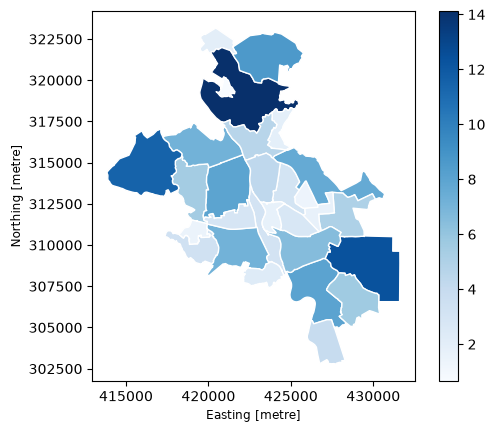

In [6]:
districts = gpd.read_file("dane/opole_districts.geojson")
districts = districts.to_crs("EPSG:2180")
districts["area_km2"] = districts.area / 1e6
print("Powierzchnia miasta:", round(districts.area.sum() / 1e6, 1), "km²")
display(districts[["name", "area_km2"]].sort_values("area_km2", ascending=False).head(10))
districts.plot(column="area_km2", cmap="Blues", legend=True, edgecolor="white")

## 7. Złączenie przestrzenne (`sjoin`)

In [7]:
joined = gpd.sjoin(sensors_m, districts[["name", "geometry"]], predicate="within")
stats = joined.groupby("name").agg(pm25_mean=("pm25", "mean"), sensor_count=("pm25", "size"))
summary = districts.merge(stats, on="name")
display(summary[["name", "pm25_mean", "sensor_count"]].sort_values("pm25_mean", ascending=False).head(5))
print("Najwyższa średnia PM2.5:", stats["pm25_mean"].idxmax(), round(stats["pm25_mean"].max(), 1), "µg/m³")
summary.explore(column="pm25_mean", cmap="Oranges", scheme="quantiles", k=5)

,name,pm25_mean,sensor_count
15,Stare Miasto,29.633333,3
23,Śródmieście,26.785714,7
22,Zaodrze,22.533333,6
12,Nadodrze,22.411111,9
21,Zakrzów,20.753846,13


Najwyższa średnia PM2.5: Stare Miasto 29.6 µg/m³


## 8. Bufory — czujniki przy szkołach

,mean,size
name,,
Publiczna Szkoła Podstawowa nr 1 im. Obrońców Westerplatte,30.700000,2
Publiczna Szkoła Podstawowa nr 21 im. Obrońców Pokoju,30.433333,3
Publiczna Szkoła Podstawowa nr 2 im. Polskich Olimpijczyków,22.100000,2
Szkoła Podstawowa nr 14,21.600000,2
Niepubliczna Szkoła Podstawowa Nasza Szkoła,20.700000,2
Szkoła Podstawowa nr 7,20.400000,3
Publiczna Szkoła Podstawowa nr 10 im. Henryka Sienkiewicza,20.250000,2
Publiczna Szkoła Podstawowa nr 5,19.300000,1
Publiczna Szkoła Podstawowa nr 15,19.100000,1


Średnia PM2.5 przy szkołach: 22.3 µg/m³
Szkoły z czujnikami w buforze: 11 / 19
Udział miasta w buforach: 9.5 %


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

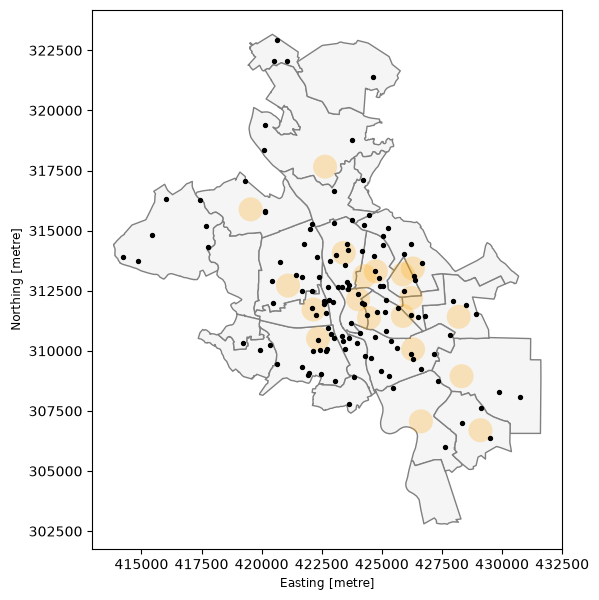

In [8]:
schools = gpd.read_file("dane/opole_schools.geojson").to_crs("EPSG:2180")
buffers = schools.copy()
buffers["geometry"] = schools.buffer(500)  # promień 500 m

nearby = gpd.sjoin(sensors_m, buffers[["name", "geometry"]], predicate="within")
school_stats = nearby.groupby("name")["pm25"].agg(["mean", "size"])
display(school_stats.sort_values("mean", ascending=False))
print("Średnia PM2.5 przy szkołach:", round(nearby["pm25"].mean(), 1), "µg/m³")
print("Szkoły z czujnikami w buforze:", len(school_stats), "/", len(schools))
print("Udział miasta w buforach:", round(buffers.union_all().area / districts.union_all().area * 100, 1), "%")

ax = districts.plot(color="whitesmoke", edgecolor="gray", figsize=(9, 7))
buffers.plot(ax=ax, color="orange", alpha=0.25)
sensors_m.plot(ax=ax, markersize=8, color="black")

## 9. Eksport wyników

In [9]:
from pathlib import Path
Path("wyniki").mkdir(exist_ok=True)
Path("wyniki/pm25_districts.gpkg").unlink(missing_ok=True)

summary.to_file("wyniki/pm25_districts.gpkg", layer="districts", driver="GPKG")
sensors_m.to_file("wyniki/pm25_districts.gpkg", layer="sensors", driver="GPKG", mode="a")
summary.to_crs("EPSG:4326").to_file("wyniki/pm25_districts.geojson", driver="GeoJSON")
print("Zapisano GeoPackage (2 warstwy) oraz GeoJSON w folderze wyniki/")

Zapisano GeoPackage (2 warstwy) oraz GeoJSON w folderze wyniki/
